# Gesture Volume Controller: turning a pinch into a trustworthy knob

**The question:** the classic computer-vision demo: hold your hand up to the webcam and **pinch your thumb and index finger** together or apart to turn the volume down or up. The legacy script measures the distance between the two fingertips **in pixels**, maps a fixed range (17 to 200 pixels) to the volume and sets it on every frame. It works on the day it is built. *But does a pixel distance mean the same thing when you sit further back? How accurately does the tracker read a pinch? And does the volume jitter when your hand holds still, and what does smoothing it cost?* We answer with **hand-labelled keypoints** as the ground truth, hands moved to different distances from the camera, and a simulation of gestures.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit: the hands and the pinch
4. Hypotheses and why we chose each test
5. The tools
6. H1: does the knob depend on how far you sit?
7. H2: how accurately does the tracker read a pinch?
8. H3: what does smoothing buy and cost?
9. Takeaways
10. Limitations

**Run it:** `uv run jupyter lab CV/gesture-volume-controller/gesture_volume_controller.ipynb`, or *Run All* in any Jupyter. The photographs (about 180 MB) and the 8 MB hand model download themselves on the first run; it takes about 12 minutes on a CPU. MediaPipe needs the system library `libgles2` (`sudo apt install libgles2` on Debian or Ubuntu). No audio device or webcam is needed: the volume is computed, not set.

## 1. 💡 The simple analogy

Imagine a **volume knob that you turn by holding two fingers apart**, measured with a ruler held against a window.

- If you **sit further back**, your fingers look smaller in the window, so the same finger gap reads as a smaller number on the ruler. A knob that uses the **ruler reading** changes its setting just because you moved your chair.
- A better knob measures the finger gap **in hand-widths**: "my fingers are as far apart as my palm is long". Move the chair and both the gap and the palm shrink together, so the answer stays put.
- Then there is **hand tremor**: even a still hand makes the reading wobble a little. Smoothing calms it, but a heavy smoothing makes the knob **slow to follow** you, like a car with sluggish steering.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the frame size and the legacy pixel range keeps the notebook reproducible and avoids "magic numbers". Frames are **640 pixels** on the longer side (a webcam), a hand counts as trackable if it fills at least **10% of the frame**, and "moving away from the camera" is simulated by shrinking the scene to 70% or 50% of the frame size on a grey background.

In [1]:
# ruff: noqa: E402 (the settings below must come before the imports that read them)
import os
import warnings

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
import contextlib
import json
import sys
import urllib.request
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import snapshot_download
from huggingface_hub.utils import logging as hub_logging
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
from scipy import stats

hub_logging.set_verbosity_error()

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 365
CANVAS = 640  # the longer side of a webcam frame, in pixels
MIN_SIZE = 0.10  # hands smaller than this share of the frame are too small to track reliably
SCALES = [1.0, 0.7, 0.5]  # how far the hand is from the camera (1 = close, 0.5 = twice as far)
IOU_MATCH = 0.5
LEGACY_MIN_PX, LEGACY_MAX_PX = 17, 200  # the legacy script's pinch range, in pixels
N_NOISY_COPIES = 15  # noisy copies of one frame, to measure the tracker's jitter
N_NOISE_HANDS = 40
N_SEQUENCES, N_FRAMES, FPS = 60, 240, 30
MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/"
    "hand_landmarker.task"
)
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Audit: the hands and the pinch

*What:* the ground truth is the CMU hand-keypoint test set (846 hands, 21 manually placed keypoints each, from everyday photographs and sign-language frames), hosted on Hugging Face. We define the **pinch opening** as the thumb-tip-to-index-tip distance **divided by the palm length** (wrist to the base of the middle finger): 0 is a closed pinch and about 1 is a wide-open hand. We keep the hands that fill at least 10% of the frame, and split the *photographs* in half: one half only to learn the volume range, the other half to evaluate. *Why:* the labels let us check the tracker against the truth, which a webcam demo cannot.

> **Problems in the legacy scripts this replaces:** the pinch range of **17 to 200 pixels is hard-coded** for one camera and one distance; the volume is set on every frame with no smoothing; the audio call (`pycaw`) only works on Windows; `mp.solutions.hands` **no longer exists** in current MediaPipe; the model was created again on every call; and nothing was ever measured.

In [2]:
if not (DATA_DIR / "hk" / "samples.json").exists():
    snapshot_download(
        "Voxel51/hand-keypoints",
        repo_type="dataset",
        local_dir=DATA_DIR / "hk",
        allow_patterns=["*.json", "*.jpg"],
    )
if not (DATA_DIR / "hand_landmarker.task").exists():
    urllib.request.urlretrieve(MODEL_URL, DATA_DIR / "hand_landmarker.task")

PALM_BASE, MIDDLE_BASE, THUMB_TIP, INDEX_TIP = 0, 9, 4, 8  # MediaPipe / CMU landmark numbers


def pinch_ratio(pts: np.ndarray) -> float:
    """Thumb-to-index distance divided by the palm length (wrist to middle-finger base).

    Args:
        pts: 21 x 2 landmark positions.

    Returns:
        The pinch opening in palm lengths: 0 is a closed pinch, about 1 a wide-open hand.
    """
    return float(
        np.linalg.norm(pts[THUMB_TIP] - pts[INDEX_TIP])
        / np.linalg.norm(pts[PALM_BASE] - pts[MIDDLE_BASE])
    )


samples = json.loads((DATA_DIR / "hk" / "samples.json").read_text())["samples"]
rows = []
for s in samples:
    side = "right" if s.get("right_hand") else "left"
    path = DATA_DIR / "hk" / s["filepath"]
    height, width = cv2.imread(str(path)).shape[:2]
    norm = np.array(s[f"{side}_hand"]["keypoints"][0]["points"])
    px = norm * [width, height]
    rows.append(
        {
            "path": path,
            "image": path.stem[:-2],
            "norm": norm,
            "size": max(np.ptp(px[:, 0]), np.ptp(px[:, 1])) / max(width, height),
            "true_ratio": pinch_ratio(px),
        }
    )
hands = pd.DataFrame(rows)
usable = hands[hands["size"] >= MIN_SIZE].copy()
images = usable["image"].unique()
calibration_images = set(rng.permutation(images)[: len(images) // 2])
usable["split"] = np.where(usable["image"].isin(calibration_images), "calibration", "evaluation")
print(
    f"{len(hands)} labelled hands; {len(usable)} are at least {MIN_SIZE:.0%} of the frame "
    f"(median size {usable['size'].median():.1%})"
)
print(usable["split"].value_counts().to_string())
print(
    "Pinch opening measured on the hand-labelled keypoints (palm lengths): "
    "5th {:.2f}, 25th {:.2f}, median {:.2f}, 75th {:.2f}, 95th {:.2f}".format(
        *usable["true_ratio"].quantile([0.05, 0.25, 0.5, 0.75, 0.95])
    )
)

846 labelled hands; 315 are at least 10% of the frame (median size 12.3%)
split
calibration    163
evaluation     152
Pinch opening measured on the hand-labelled keypoints (palm lengths): 5th 0.27, 25th 0.53, median 0.84, 75th 1.08, 95th 1.88


**How to read this:**

- **315 of the 846 hands** fill at least 10% of the frame (median **12.3%**); they come from **163 hands in the calibration half and 152 in the evaluation half** (split by photograph, so no photograph appears in both).
- **The pinch opening of real hands:** on the hand-labelled keypoints, the 5th percentile is **0.27** palm lengths, the median **0.84** and the 95th percentile **1.88**. This is the range a good controller should cover.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does the pinch reading change when the hand is further from the camera, in pixels and in palm lengths? | No change | It changes (for pixels) | Per-hand log of far/close ratio against 'no change' (Wilcoxon); Friedman test across 3 distances on the resulting volume |
| H2 | Does the tracker's pinch agree with the hand-labelled pinch? | No agreement | Strong agreement, with some error | Spearman correlation; Bland-Altman bias and limits; volume error in points; Kruskal-Wallis across hand sizes |
| H3 | Does smoothing reduce the jitter of the volume, and what does it cost in delay? | Same jitter and delay | Less jitter, more delay | Paired Wilcoxon over 60 simulated gestures; jitter measured from real noisy frames |

*Why these tests?* The same hand is measured at three distances, so the data are **paired** and the Friedman and Wilcoxon tests, which compare each hand with itself, are the right tools. Pinch openings are skewed, so we use **rank-based** tests. For agreement with the labels, correlation alone is not enough (two signals can correlate and still disagree by a lot), so we add the **Bland-Altman** bias and limits of agreement and the error in the units that matter (volume points).

## 5. The tools

*What:* MediaPipe's current **HandLandmarker** (the "Tasks" API that replaced `mp.solutions.hands`), created **once**, and a few helpers: `pinch_ratio` (thumb-to-index distance in palm lengths), `frame_at_distance` (a webcam-sized frame in which the scene is shrunk to simulate a hand moving away) and `locate` (the detected hand that overlaps the labelled hand). A hand is "found" when its landmark box overlaps the labelled box by an IoU of at least 0.5. *Why:* because the camera frame stays the same size while the hand shrinks, this is exactly what happens when you lean back from a webcam.

In [3]:
@contextlib.contextmanager
def silence_native_logs():
    """Hides messages that compiled libraries write straight to the terminal (file descriptor 2)."""
    sys.stderr.flush()
    saved, devnull = os.dup(2), os.open(os.devnull, os.O_WRONLY)
    os.dup2(devnull, 2)
    try:
        yield
    finally:
        os.dup2(saved, 2)
        os.close(devnull)
        os.close(saved)


with silence_native_logs():
    landmarker = vision.HandLandmarker.create_from_options(
        vision.HandLandmarkerOptions(
            base_options=mp_python.BaseOptions(
                model_asset_path=str(DATA_DIR / "hand_landmarker.task")
            ),
            num_hands=4,
        )
    )


def detect(rgb: np.ndarray) -> list[np.ndarray]:
    """Finds hands in one RGB image; returns each hand's 21 x 2 landmark pixel positions."""
    h, w = rgb.shape[:2]
    with silence_native_logs():
        result = landmarker.detect(
            mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb))
        )
    return [np.array([[p.x * w, p.y * h] for p in lms]) for lms in result.hand_landmarks]


def box_iou(a: np.ndarray, b: np.ndarray) -> float:
    """Intersection over union of the boxes around two sets of landmark points."""
    a, b = np.r_[a.min(0), a.max(0)], np.r_[b.min(0), b.max(0)]
    iw = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    ih = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    return inter / max((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter, 1e-9)


def frame_at_distance(path: Path, scale: float) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Builds a webcam-sized frame in which the scene is `scale` times as large (further away).

    The photograph is first resized so its longer side is CANVAS pixels; for scale < 1 it is
    shrunk and centred on a grey canvas of the same size, like a hand moving away from a camera
    whose frame stays the same.

    Args:
        path: The photograph.
        scale: Distance factor (1 = as shot, 0.5 = twice as far).

    Returns:
        The RGB frame and the (x, y) offset and size of the pasted photograph in it.
    """
    rgb = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    k = CANVAS / max(rgb.shape[:2])
    base = cv2.resize(rgb, None, fx=k, fy=k, interpolation=cv2.INTER_AREA)
    h, w = base.shape[:2]
    frame = np.full_like(base, 114)
    small = cv2.resize(base, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    sh, sw = small.shape[:2]
    y0, x0 = (h - sh) // 2, (w - sw) // 2
    frame[y0 : y0 + sh, x0 : x0 + sw] = small
    return frame, np.array([x0, y0]), np.array([sw, sh])


def locate(frame: np.ndarray, truth: np.ndarray) -> np.ndarray | None:
    """The detected hand that overlaps the true hand enough to count, or None."""
    best = max(detect(frame), key=lambda p: box_iou(p, truth), default=None)
    return best if best is not None and box_iou(best, truth) >= IOU_MATCH else None


print("Landmarker ready; `frame_at_distance` moves a hand away from the camera.")

Landmarker ready; `frame_at_distance` moves a hand away from the camera.


**How to read this:** the landmarker loads once and is ready. (Messages that MediaPipe's compiled code prints straight to the terminal are hidden so the notebook output stays clean.)

## 6. H1: does the knob depend on how far you sit?

*What:* take each trackable hand at three distances (1.0 = as photographed, 0.7, 0.5 = twice as far) and keep the hands the tracker finds at **all three**, so every hand is compared with itself. Measure the thumb-to-index distance **in pixels** (the legacy rule: volume = (pixels - 17) / (200 - 17)) and **in palm lengths** (volume = the opening mapped from the 5th-to-95th percentile range of the labelled calibration half). We use the evaluation half only. *Why:* if the knob depends on distance, the user must sit exactly where the developer sat.

In [4]:
records = []
for k, row in usable.iterrows():
    per_scale = {}
    for scale in SCALES:
        frame, offset, size = frame_at_distance(row["path"], scale)
        truth = row["norm"] * size + offset
        found = locate(frame, truth)
        per_scale[scale] = (truth, found)
    if all(f is not None for _, f in per_scale.values()):
        for scale, (truth, found) in per_scale.items():
            records.append(
                {
                    "hand": k,
                    "split": row["split"],
                    "scale": scale,
                    "size": row["size"],
                    "px": np.linalg.norm(found[4] - found[8]),
                    "ratio": pinch_ratio(found),
                    "true_ratio": pinch_ratio(truth),
                }
            )
    else:
        records.append({"hand": k, "split": row["split"], "scale": None})
runs = pd.DataFrame(records)
lost = runs[runs["scale"].isna()]
tracked = runs.dropna(subset=["scale"])
print(
    f"Hands found at all three distances: {tracked['hand'].nunique()} of {len(usable)} "
    f"({tracked['hand'].nunique() / len(usable):.0%}); the other {len(lost)} are dropped from "
    "this section so every hand is compared with itself"
)

calib = tracked[(tracked["split"] == "calibration") & (tracked["scale"] == 1.0)]
RATIO_LOW, RATIO_HIGH = calib["true_ratio"].quantile([0.05, 0.95])
print(
    f"Pinch range learned from the labelled calibration half: {RATIO_LOW:.2f} (volume 0) to "
    f"{RATIO_HIGH:.2f} (volume 100) palm lengths"
)


def volume_from_pixels(px: np.ndarray) -> np.ndarray:
    """The legacy rule: a fixed pixel range mapped to 0-100."""
    return np.clip((px - LEGACY_MIN_PX) / (LEGACY_MAX_PX - LEGACY_MIN_PX), 0, 1) * 100


def volume_from_ratio(ratio: np.ndarray) -> np.ndarray:
    """The palm-normalised rule: a range of pinch openings mapped to 0-100."""
    return np.clip((ratio - RATIO_LOW) / (RATIO_HIGH - RATIO_LOW), 0, 1) * 100


tracked = tracked.assign(
    vol_legacy=volume_from_pixels(tracked["px"]), vol_ratio=volume_from_ratio(tracked["ratio"])
)
test = tracked[tracked["split"] == "evaluation"]
wide = test.pivot(index="hand", columns="scale", values=["px", "ratio", "vol_legacy", "vol_ratio"])
print(f"\nEvaluation half: {len(wide)} hands, each seen at three distances")
summary = pd.DataFrame(
    {
        "median pinch (pixels)": wide["px"].median(),
        "legacy volume (mean)": wide["vol_legacy"].mean(),
        "palm-normalised volume (mean)": wide["vol_ratio"].mean(),
    }
)
print(summary.round(1).to_string())
for name in ("vol_legacy", "vol_ratio"):
    fr = stats.friedmanchisquare(*[wide[name][s] for s in SCALES])
    drift = (wide[name][0.5] - wide[name][1.0]).abs()
    print(
        f"{name}: Friedman across distances chi2 = {fr.statistic:.1f}, p = {fmt_p(fr.pvalue)}; "
        f"median change of the volume from close to far: {drift.median():.1f} points "
        f"(mean {drift.mean():.1f})"
    )
d_legacy = (wide["vol_legacy"][0.5] - wide["vol_legacy"][1.0]).abs()
d_ratio = (wide["vol_ratio"][0.5] - wide["vol_ratio"][1.0]).abs()
wil = stats.wilcoxon(d_legacy, d_ratio)
print(
    f"Paired Wilcoxon on |volume change| legacy vs palm-normalised: p = {fmt_p(wil.pvalue)}; "
    f"legacy changes more in {(d_legacy > d_ratio).mean():.0%} of hands"
)
for label, col in (("pinch in pixels", "px"), ("pinch in palm lengths", "ratio")):
    change = np.log2(wide[col][0.5] / wide[col][1.0])
    wz = stats.wilcoxon(change)
    print(
        f"{label}: at half the distance it is {2 ** change.median():.2f} times its "
        f"close-up value (median over hands; Wilcoxon against 'no change' "
        f"p = {fmt_p(wz.pvalue)})"
    )
reach = (wide["px"][1.0] >= LEGACY_MAX_PX).mean()
print(
    f"Hands whose own measured pinch reaches the legacy 200-pixel ceiling when close: {reach:.0%}"
)

Hands found at all three distances: 244 of 315 (77%); the other 71 are dropped from this section so every hand is compared with itself
Pinch range learned from the labelled calibration half: 0.32 (volume 0) to 1.85 (volume 100) palm lengths

Evaluation half: 115 hands, each seen at three distances
       median pinch (pixels)  legacy volume (mean)  palm-normalised volume (mean)
scale                                                                            
0.5                     16.1                   1.4                           33.3
0.7                     22.9                   4.2                           33.3
1.0                     32.2                   9.0                           33.0
vol_legacy: Friedman across distances chi2 = 170.1, p = 1.2e-37; median change of the volume from close to far: 7.8 points (mean 7.6)
vol_ratio: Friedman across distances chi2 = 2.9, p = 2.4e-01; median change of the volume from close to far: 3.4 points (mean 7.4)
Paired Wilcoxon on |volume

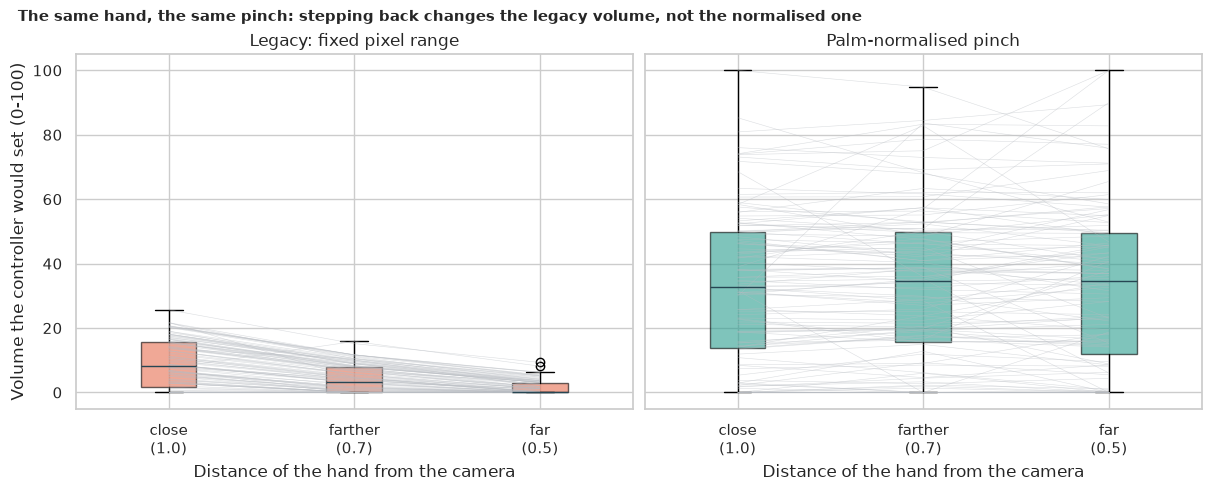

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, layout="constrained")
for ax, name, title, color in [
    (axes[0], "vol_legacy", "Legacy: fixed pixel range", ORANGE),
    (axes[1], "vol_ratio", "Palm-normalised pinch", TEAL),
]:
    data = [wide[name][s].to_numpy() for s in SCALES]
    ax.boxplot(
        data,
        tick_labels=["close\n(1.0)", "farther\n(0.7)", "far\n(0.5)"],
        patch_artist=True,
        boxprops={"facecolor": color, "alpha": 0.6},
        medianprops={"color": NAVY},
    )
    for i in range(len(wide)):
        ax.plot(range(1, 4), [wide[name][s].iloc[i] for s in SCALES], color=GREY, lw=0.4, alpha=0.5)
    ax.set_title(title)
    ax.set_xlabel("Distance of the hand from the camera")
axes[0].set_ylabel("Volume the controller would set (0-100)")
fig.suptitle(
    "The same hand, the same pinch: stepping back changes the legacy volume, "
    "not the normalised one",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "01_distance.png", dpi=150)
plt.show()

**How to read this:**

- **244 of the 315 hands (77%) are found at all three distances;** the evaluation half has **115** of them. The pinch range learned from the calibration half is **0.32 to 1.85** palm lengths.
- **A pixel distance halves when the distance doubles:** the median pinch is **32.2** pixels close up, **22.9** at 0.7 and **16.1** at 0.5. At half the distance it is **0.50 times** its close-up value (Wilcoxon against "no change" p = 2e-19).
- **A palm-normalised pinch does not change:** at half the distance it is **0.98 times** its close-up value (p = 0.69, no detectable change). The volume computed from it averages **33.0, 33.3 and 33.3** at the three distances (Friedman p = 0.24). The legacy volume averages **9.0, 4.2 and 1.4** (Friedman p = 1e-37): moving back switches the knob down. **We reject H₀ for pixels, and not for palm lengths.**
- **A second problem shows up: the legacy range does not fit these hands.** The median pinch is only 32 pixels at this camera framing, so the legacy volume sits near the bottom (mean **9.0**) and **0%** of the hands ever reach the 200-pixel ceiling. A hand held very close to the webcam would be larger, which is exactly the point: the constants only fit the developer's setup.
- **A caution about a comparison we did not win:** the median *volume change* from close to far is similar for both rules (legacy 7.8 points, palm-normalised 3.4; mean 7.6 against 7.4; paired Wilcoxon p = 0.10), because the legacy volume is squashed near 0 and cannot fall further. The comparison in the pinch itself (0.50 against 0.98 times) is the clean one.

## 7. H2: how accurately does the tracker read a pinch?

*What:* for the 115 evaluation hands at the close distance, compare the pinch opening MediaPipe reports with the one computed from the hand-labelled keypoints: Spearman correlation, the Bland-Altman bias and 95% limits of agreement, and the **volume error in points** (0 to 100) at each distance. We also split the hands by size into three equal groups and test whether the error differs (Kruskal-Wallis). *Why:* a good-looking skeleton on screen does not say how well the thumb and index tips are placed.

In [6]:
close = test[test["scale"] == 1.0]
rho = stats.spearmanr(close["ratio"], close["true_ratio"])
diff = close["ratio"] - close["true_ratio"]
bias, spread = diff.mean(), 1.96 * diff.std()
print(f"Pinch opening, MediaPipe vs hand-labelled keypoints ({len(close)} close hands):")
print(f"  Spearman correlation {rho.statistic:+.2f}, p = {fmt_p(rho.pvalue)}")
print(
    f"  bias {bias:+.3f} palm lengths; 95% of differences within {bias - spread:+.3f} to "
    f"{bias + spread:+.3f}"
)
errors = []
for scale in SCALES:
    sub = test[test["scale"] == scale]
    err = (sub["vol_ratio"] - volume_from_ratio(sub["true_ratio"])).abs()
    errors.append(err.rename(scale))
    print(
        f"  distance {scale}: volume error median {err.median():.1f} points, "
        f"mean {err.mean():.1f}, within 10 points for {(err <= 10).mean():.0%} of hands"
    )
sub = close.assign(err=(close["vol_ratio"] - volume_from_ratio(close["true_ratio"])).abs())
sub["size tercile"] = pd.qcut(sub["size"], 3, labels=["smallest", "middle", "largest"])
groups = [g["err"].to_numpy() for _, g in sub.groupby("size tercile", observed=True)]
kw = stats.kruskal(*groups)
print(
    "  mean volume error by hand-size tercile: "
    + ", ".join(
        f"{n} {g.mean():.1f}"
        for n, g in zip(["smallest", "middle", "largest"], groups, strict=True)
    )
    + f"; Kruskal-Wallis p = {fmt_p(kw.pvalue)}"
)

Pinch opening, MediaPipe vs hand-labelled keypoints (115 close hands):
  Spearman correlation +0.90, p = 2.1e-42
  bias -0.060 palm lengths; 95% of differences within -0.591 to +0.471
  distance 1.0: volume error median 6.8 points, mean 9.3, within 10 points for 68% of hands
  distance 0.7: volume error median 7.4 points, mean 10.1, within 10 points for 62% of hands
  distance 0.5: volume error median 6.9 points, mean 10.9, within 10 points for 63% of hands
  mean volume error by hand-size tercile: smallest 8.2, middle 7.6, largest 12.1; Kruskal-Wallis p = 2.4e-01


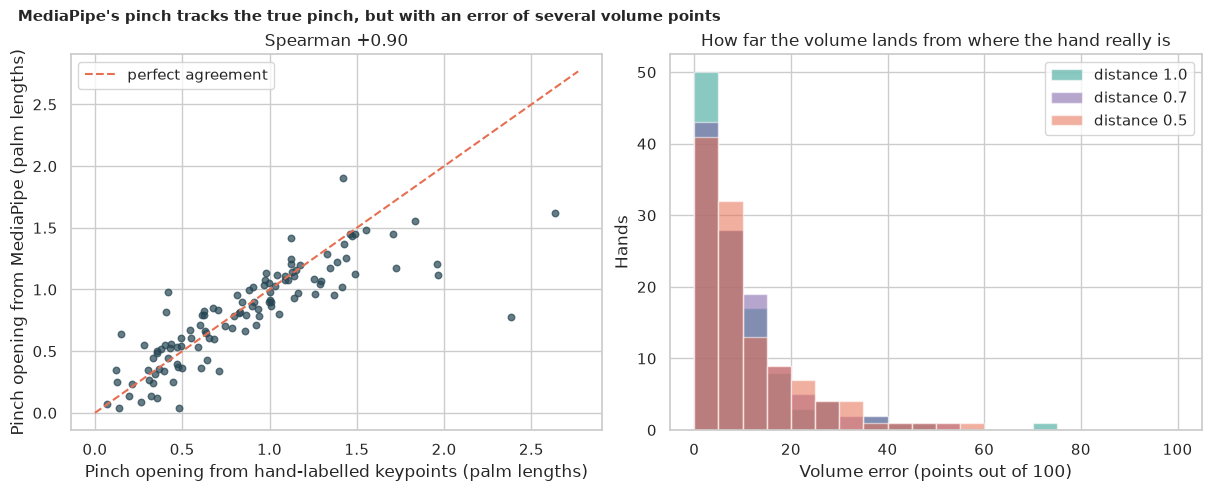

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
axes[0].scatter(close["true_ratio"], close["ratio"], s=22, color=NAVY, alpha=0.7)
top = max(close["true_ratio"].max(), close["ratio"].max()) * 1.05
axes[0].plot([0, top], [0, top], color=ORANGE, ls="--", label="perfect agreement")
axes[0].set_xlabel("Pinch opening from hand-labelled keypoints (palm lengths)")
axes[0].set_ylabel("Pinch opening from MediaPipe (palm lengths)")
axes[0].set_title(f"Spearman {rho.statistic:+.2f}")
axes[0].legend()
for scale, color in zip(SCALES, [TEAL, PURPLE, ORANGE], strict=True):
    err = pd.concat(errors, axis=1)[scale].dropna()
    axes[1].hist(
        err, bins=np.linspace(0, 100, 21), alpha=0.55, color=color, label=f"distance {scale}"
    )
axes[1].set_xlabel("Volume error (points out of 100)")
axes[1].set_ylabel("Hands")
axes[1].set_title("How far the volume lands from where the hand really is")
axes[1].legend()
fig.suptitle(
    "MediaPipe's pinch tracks the true pinch, but with an error of several volume points",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "02_accuracy.png", dpi=150)
plt.show()

**How to read this:**

- **The tracker's pinch follows the true pinch:** Spearman correlation **+0.90** (p = 2e-42). The scatter plot clusters around the diagonal.
- **But individual readings can be far off:** the bias is small (**-0.060** palm lengths) but 95% of the differences lie between **-0.591 and +0.471** palm lengths, a wide band, because fingertip landmarks are the least precise (the hand-detection notebook measured it) and a pinch is a small distance between two of them.
- **In volume points:** the median error is **6.8** points out of 100 close up (mean 9.3), with **68%** of hands within 10 points. Further away it is similar: **7.4** (62% within 10 points) at distance 0.7 and **6.9** (63%) at 0.5, so palm normalisation keeps the *level* right but the reading gets slightly noisier.
- **The error does not clearly depend on hand size:** the mean volume error is **8.2, 7.6 and 12.1** points for the smallest, middle and largest hands, with Kruskal-Wallis p = **0.24** (not significant). We do not reject H₀ for size; for the agreement itself, **we reject H₀**.
- **In practice:** a controller built on this pinch needs a margin (a dead zone or smoothing), because a still, wide-open hand can read ±10 points off the truth.

## 8. H3: what does smoothing buy and cost?

*What:* even a perfectly still hand makes the reading wobble. We measure it from **real** tracker output: take 40 evaluation hands, make **15 noisy copies of each frame** (sensor noise, a ±10% brightness change and JPEG compression), run the tracker, and take the median spread of the pinch opening as the tracker's frame-to-frame jitter, plus how often the hand is lost. Then we simulate **60 gestures of 8 seconds** (30 frames per second; hold, glide to a new opening in 12 frames, hold again), add that jitter and those dropouts to the true pinch, and pass the result through five filters: none, an **exponential moving average** (weights 0.5, 0.2, 0.1) and the **One Euro filter** (which smooths hard when the signal is still and lightly when it moves). *Jitter* is the wobble of the volume while the hand holds still (spread of the last 20 frames of each hold around a straight line); *lag* is how many frames the output needs to get within 10 points of a new value. *Why:* it shows the trade-off a designer faces.

In [8]:
def add_noise(frame: np.ndarray) -> np.ndarray:
    """A noisy copy of a frame: sensor noise, a small brightness change and JPEG compression."""
    noisy = frame.astype(np.float32) * rng.uniform(0.9, 1.1) + rng.normal(0, 6, frame.shape)
    noisy = np.clip(noisy, 0, 255).astype(np.uint8)
    ok, buf = cv2.imencode(".jpg", noisy, [cv2.IMWRITE_JPEG_QUALITY, 60])
    return cv2.imdecode(buf, cv2.IMREAD_COLOR)


noise_hands = test[test["scale"] == 1.0]["hand"].to_numpy()[:N_NOISE_HANDS]
spreads, dropped, total = [], 0, 0
for k in noise_hands:
    frame, offset, size = frame_at_distance(usable.loc[k, "path"], 1.0)
    truth = usable.loc[k, "norm"] * size + offset
    series = []
    for _ in range(N_NOISY_COPIES):
        found = locate(add_noise(frame), truth)
        total += 1
        if found is None:
            dropped += 1
        else:
            series.append(pinch_ratio(found))
    if len(series) > 3:
        spreads.append(np.std(series))
SIGMA = float(np.median(spreads))
DROPOUT = dropped / total
unit = 100 / (RATIO_HIGH - RATIO_LOW)
print(f"Same frame, {N_NOISY_COPIES} noisy copies, {len(noise_hands)} hands:")
print(
    f"  frame-to-frame spread of the pinch opening: median {SIGMA:.3f} palm lengths "
    f"(= {SIGMA * unit:.1f} volume points); worst hand {max(spreads):.3f}"
)
print(f"  hand lost in {DROPOUT:.1%} of the noisy frames")

Same frame, 15 noisy copies, 40 hands:
  frame-to-frame spread of the pinch opening: median 0.036 palm lengths (= 2.3 volume points); worst hand 0.223
  hand lost in 0.2% of the noisy frames


In [9]:
def ema(x: np.ndarray, alpha: float) -> np.ndarray:
    """Exponential moving average: alpha of the new value plus the rest of the old output."""
    out = np.empty_like(x)
    out[0] = x[0]
    for i in range(1, len(x)):
        out[i] = alpha * x[i] + (1 - alpha) * out[i - 1]
    return out


def one_euro(x: np.ndarray, min_cutoff: float = 1.0, beta: float = 0.05) -> np.ndarray:
    """The One Euro filter: smooth heavily when the signal is still, lightly when it moves fast.

    Args:
        x: The signal, sampled at FPS frames per second.
        min_cutoff: Cut-off frequency (Hz) when the signal is still; lower is smoother.
        beta: How fast the cut-off rises with the signal's speed.

    Returns:
        The filtered signal.
    """

    def alpha(cutoff: float) -> float:
        return 1 / (1 + (1 / (2 * np.pi * cutoff)) * FPS)

    out = np.empty_like(x)
    out[0], d_prev = x[0], 0.0
    for i in range(1, len(x)):
        d_prev = alpha(1.0) * (x[i] - out[i - 1]) * FPS + (1 - alpha(1.0)) * d_prev
        a = alpha(min_cutoff + beta * abs(d_prev))
        out[i] = a * x[i] + (1 - a) * out[i - 1]
    return out


FILTERS = {
    "no smoothing": lambda x: x,
    "EMA 0.5": lambda x: ema(x, 0.5),
    "EMA 0.2": lambda x: ema(x, 0.2),
    "EMA 0.1": lambda x: ema(x, 0.1),
    "One Euro": one_euro,
}


def settled_jitter(out: np.ndarray, hold: np.ndarray) -> float:
    """Wobble of a signal during holds, ignoring slow drifts: the spread of the last 20 frames of
    each hold around a straight line."""
    spreads = []
    for end in np.flatnonzero(hold[:-1] & ~hold[1:]) + 1:
        segment = out[end - 20 : end]
        line = np.polyval(np.polyfit(np.arange(20), segment, 1), np.arange(20))
        spreads.append(np.std(segment - line))
    return float(np.mean(spreads))


def make_gesture() -> tuple[np.ndarray, np.ndarray]:
    """A random sequence of pinches: hold, glide to a new opening in 12 frames, hold again.

    Returns:
        The true volume (0-100) per frame and a flag marking frames inside a hold.
    """
    targets = rng.uniform(5, 95, N_FRAMES // 40 + 2)
    truth, hold = [], []
    for a, b in zip(targets[:-1], targets[1:], strict=True):
        glide = a + (b - a) * (1 - np.cos(np.linspace(0, np.pi, 12))) / 2
        truth += [a] * 28 + list(glide)
        hold += [True] * 28 + [False] * 12
    return np.array(truth[:N_FRAMES]), np.array(hold[:N_FRAMES])


def measure(truth: np.ndarray) -> np.ndarray:
    """What the tracker reports: truth plus measured jitter, holding the last value on a drop."""
    seen = truth + rng.normal(0, SIGMA * unit, len(truth))
    for i in range(1, len(seen)):
        if rng.random() < DROPOUT:
            seen[i] = seen[i - 1]
    return np.clip(seen, 0, 100)


def lag_frames(truth: np.ndarray, out: np.ndarray, hold: np.ndarray) -> float:
    """Average frames a filter needs to get within 10 points of the new value after each glide."""
    delays = []
    for start in np.flatnonzero(hold[:-1] & ~hold[1:]):
        end = start + 1 + 12 + 28
        target = truth[min(start + 13, N_FRAMES - 1)]
        window = out[start + 1 : min(end, N_FRAMES)]
        close = np.flatnonzero(np.abs(window - target) <= 10)
        delays.append(close[0] + 1 if len(close) else len(window))
    return float(np.mean(delays)) if delays else np.nan


rows = []
example = None
for seq in range(N_SEQUENCES):
    truth, hold = make_gesture()
    seen = measure(truth)
    for name, fn in FILTERS.items():
        out = fn(seen)
        rows.append(
            {
                "sequence": seq,
                "filter": name,
                "jitter": settled_jitter(out, hold),
                "rmse": np.sqrt(np.mean((out - truth) ** 2)),
                "lag": lag_frames(truth, out, hold),
            }
        )
        if seq == 0:
            example = example or {"truth": truth}
            example[name] = out
sim = pd.DataFrame(rows)
summary = sim.groupby("filter", sort=False)[["jitter", "lag", "rmse"]].mean()
print(
    f"{N_SEQUENCES} simulated gestures of {N_FRAMES} frames at {FPS} frames per second "
    f"(jitter = wobble of the volume while the hand holds still, in points)"
)
print(summary.round(2).to_string())
raw = sim[sim["filter"] == "no smoothing"].set_index("sequence")
for name in list(FILTERS)[1:]:
    other = sim[sim["filter"] == name].set_index("sequence")
    wj = stats.wilcoxon(other["jitter"], raw["jitter"])
    wl = stats.wilcoxon(other["lag"], raw["lag"])
    print(
        f"{name} vs no smoothing: jitter {other['jitter'].mean() / raw['jitter'].mean() - 1:+.0%} "
        f"(Wilcoxon p = {fmt_p(wj.pvalue)}), lag {other['lag'].mean() - raw['lag'].mean():+.1f} "
        f"frames (p = {fmt_p(wl.pvalue)}), RMSE {other['rmse'].mean() - raw['rmse'].mean():+.1f}"
    )

60 simulated gestures of 240 frames at 30 frames per second (jitter = wobble of the volume while the hand holds still, in points)
              jitter    lag  rmse
filter                           
no smoothing    2.20   6.07  2.34
EMA 0.5         1.15   6.84  2.09
EMA 0.2         0.53   8.99  5.16
EMA 0.1         0.45  12.42  8.77
One Euro        0.78   6.65  1.66
EMA 0.5 vs no smoothing: jitter -48% (Wilcoxon p = 1.6e-11), lag +0.8 frames (p = 1.5e-11), RMSE -0.2
EMA 0.2 vs no smoothing: jitter -76% (Wilcoxon p = 1.6e-11), lag +2.9 frames (p = 1.6e-11), RMSE +2.8
EMA 0.1 vs no smoothing: jitter -80% (Wilcoxon p = 1.6e-11), lag +6.4 frames (p = 1.6e-11), RMSE +6.4
One Euro vs no smoothing: jitter -65% (Wilcoxon p = 1.6e-11), lag +0.6 frames (p = 1.1e-10), RMSE -0.7


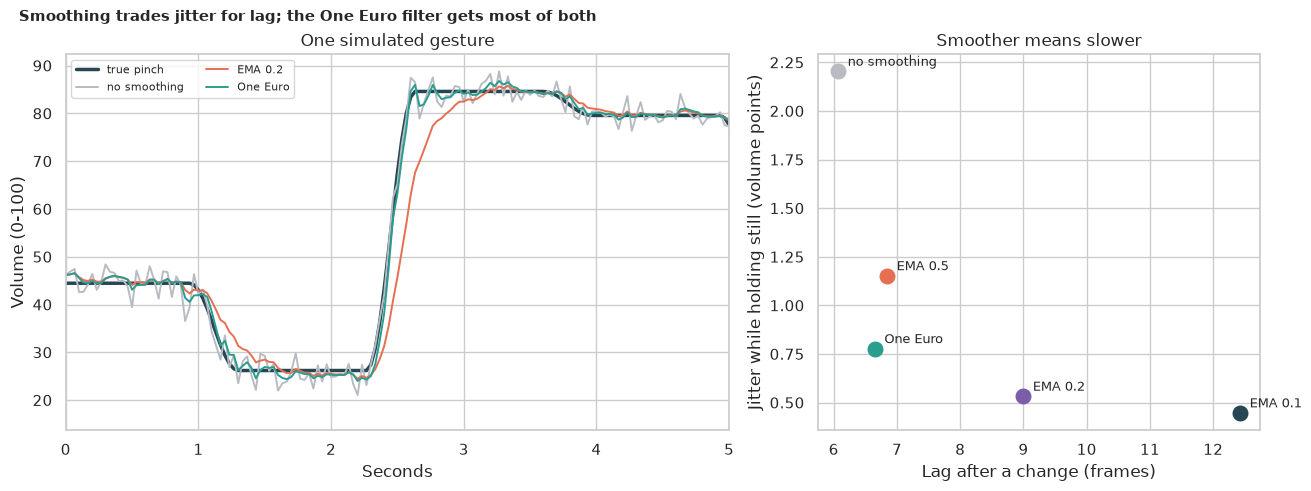

In [10]:
fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.8), layout="constrained", gridspec_kw={"width_ratios": [1.5, 1]}
)
t = np.arange(N_FRAMES) / FPS
axes[0].plot(t, example["truth"], color=NAVY, lw=2.5, label="true pinch")
for name, color in [("no smoothing", GREY), ("EMA 0.2", ORANGE), ("One Euro", TEAL)]:
    axes[0].plot(t, example[name], color=color, lw=1.4, label=name)
axes[0].set_xlim(0, 5)
axes[0].set_xlabel("Seconds")
axes[0].set_ylabel("Volume (0-100)")
axes[0].set_title("One simulated gesture")
axes[0].legend(fontsize=8, ncol=2)
colors = [GREY, ORANGE, PURPLE, NAVY, TEAL]
for (name, r), color in zip(summary.iterrows(), colors, strict=True):
    axes[1].scatter(r["lag"], r["jitter"], s=110, color=color, zorder=3)
    axes[1].annotate(
        name, (r["lag"], r["jitter"]), textcoords="offset points", xytext=(7, 4), fontsize=9
    )
axes[1].set_xlabel("Lag after a change (frames)")
axes[1].set_ylabel("Jitter while holding still (volume points)")
axes[1].set_title("Smoother means slower")
fig.suptitle(
    "Smoothing trades jitter for lag; the One Euro filter gets most of both",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "03_filters.png", dpi=150)
plt.show()

**How to read this:**

- **The tracker's own jitter is small but real:** a still hand's pinch opening has a median frame-to-frame spread of **0.036** palm lengths (**2.3** volume points; the worst hand **0.223**), and the hand is lost in **0.2%** of the noisy frames (the filters hold the last value).
- **Smoothing really reduces jitter:** raw jitter is **2.20** points; EMA 0.5 cuts it to **1.15** (-48%), EMA 0.2 to **0.53** (-76%), EMA 0.1 to **0.45** (-80%) and One Euro to **0.78** (-65%). All differences are significant in all 60 gestures (Wilcoxon p = 2e-11, the smallest value 60 pairs can give).
- **Smoothing costs delay:** the raw signal needs **6.1** frames to reach within 10 points of a new value (the glide itself takes 12); EMA 0.5 adds **0.8** frames, EMA 0.2 **2.9** and EMA 0.1 **6.4** (12.4 in all, more than a third of a second).
- **Heavy smoothing hurts accuracy overall:** the RMSE against the truth is **2.3** with no smoothing, **2.1** for EMA 0.5, **5.2** for EMA 0.2 and **8.8** for EMA 0.1, because the lag outweighs the noise it removes.
- **One Euro gets most of both:** jitter -65% for only **+0.6** frames of lag, and the **lowest** RMSE of all (**1.7**, against 2.3 raw). **We reject H₀** (less jitter, more lag), with the finding that the right filter is a design choice, not a free win.

## 9. 🎯 Takeaways

1. **A pixel distance is not a pinch:** at half the distance the same pinch reads **0.50 times** as large in pixels, but **0.98 times** (no change) when divided by the palm length. The legacy volume falls from 9.0 to 1.4 when you lean back; the palm-normalised volume stays at 33.
2. **Constants tied to one setup break in another:** the legacy range of 17 to 200 pixels is never reached by any of these hands (the median pinch is 32 pixels at this framing).
3. **The tracker reads a pinch with Spearman +0.90 but not precisely:** a typical error of 6.8 volume points, 68% of hands within 10, and 95% limits of agreement of -0.59 to +0.47 palm lengths.
4. **Smoothing trades jitter for lag:** EMA 0.5 halves the jitter for under one frame of lag; EMA 0.1 removes 80% of it but needs 6 more frames and nearly quadruples the error.
5. **A smarter filter beats a fixed one:** One Euro cuts jitter by 65% for 0.6 frames of lag and has the lowest overall error (1.7 points).
6. **Measure before you design:** each of these choices (normalise, calibrate, smooth) has a number that says whether it works, and the demo shows none of them.

## 10. ⚠️ Limitations

- **Photographs, not webcam video.** The hands come from everyday photographs and sign-language frames, and are rarely in a deliberate pinch pose; a webcam user holds the hand up and moves it.
- **Distance is simulated** by shrinking the scene on a grey canvas; a real move away changes focus, noise and perspective too.
- **Only hands found at all three distances** are compared (77% of the trackable hands), which favours easy hands.
- **The jitter model is measured on single frames with added noise,** and the gestures are simulated with independent noise from frame to frame; real tracking errors are correlated in time, so real jitter may be larger and slower.
- **The volume range (0.32 to 1.85 palm lengths)** comes from this dataset's calibration half; a real user would calibrate to their own hand.
- **The filter settings (EMA weights, One Euro 1.0 Hz and 0.05) were picked once** and not tuned.
- **The pinch is measured in 2D.** A hand turned towards or away from the camera shortens the apparent palm and changes the ratio.
- **The legacy audio call is not tested:** the volume is computed, not set, so the audio part of the legacy script is untouched.
- **No fairness check** across skin tones, ages or hand sizes.